
# Qiskit Fall Fest 2026
## Challenge 2: Make the Quantum Coin Biased

**Institution:** Vishnu Institute of Technology

### Objective
The aim of this challenge is to create a single-qubit quantum circuit and change the probabilities of measuring 0 and 1.

We will create a fair quantum coin and two biased quantum coins using Qiskit. Each circuit will be measured for 100 shots, and the results will be displayed using histograms.



## 1. Theory

A qubit can be in a quantum state:

|ψ⟩ = α|0⟩ + β|1⟩

The probabilities of measurement are:

P(0) = |α|²

P(1) = |β|²

The total probability is always 1.

- The H gate creates an equal superposition.
- The RY gate rotates the qubit and can change the measurement probabilities.
- Measurement gives the final result, either 0 or 1.

By changing the rotation angle, we can make one outcome more likely than the other.


In [12]:

%pip install qiskit qiskit-aer matplotlib


Note: you may need to restart the kernel to use updated packages.


In [13]:

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
import numpy as np

simulator = AerSimulator()

print("Libraries imported successfully!")


Libraries imported successfully!



## 2. Experiment 1 — Fair Quantum Coin

First, we create a circuit with one qubit and one classical bit.

The H gate creates an equal superposition of 0 and 1.

**Prediction:**
- P(0) = 50%
- P(1) = 50%

We execute the circuit for 100 shots. The actual counts may differ slightly from 50 and 50.


In [14]:

fair_circuit = QuantumCircuit(1, 1)

fair_circuit.h(0)
fair_circuit.measure(0, 0)

print(fair_circuit.draw())


     ┌───┐┌─┐
  q: ┤ H ├┤M├
     └───┘└╥┘
c: 1/══════╩═
           0 


In [15]:

fair_result = simulator.run(
    fair_circuit, shots=100
).result()

fair_counts = fair_result.get_counts()

print("Fair coin results:", fair_counts)
print("Total shots:", sum(fair_counts.values()))


Fair coin results: {'0': 57, '1': 43}
Total shots: 100


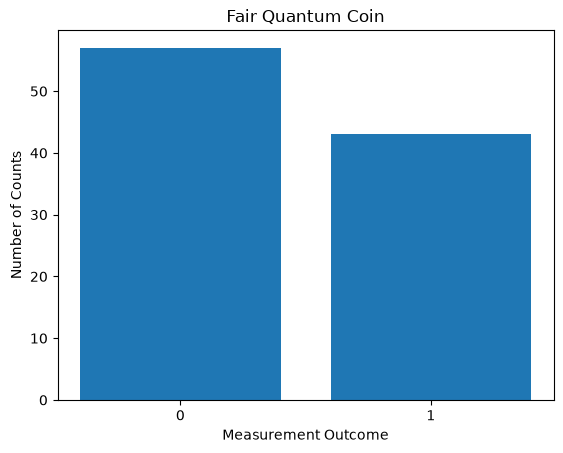

In [16]:

plt.bar(
    fair_counts.keys(),
    fair_counts.values()
)

plt.title("Fair Quantum Coin")
plt.xlabel("Measurement Outcome")
plt.ylabel("Number of Counts")
plt.show()



## 3. Experiment 2 — Make Outcome 0 More Frequent

Now, we use the RY gate with an angle of π/3.

The predicted probabilities are:

P(0) = 75%

P(1) = 25%

Therefore, outcome 0 should occur more frequently than outcome 1.

We use one qubit, one rotation gate, measurement, and 100 shots.


In [17]:

zero_circuit = QuantumCircuit(1, 1)

zero_circuit.ry(np.pi / 3, 0)
zero_circuit.measure(0, 0)

print(zero_circuit.draw())


     ┌─────────┐┌─┐
  q: ┤ Ry(π/3) ├┤M├
     └─────────┘└╥┘
c: 1/════════════╩═
                 0 


In [18]:

zero_result = simulator.run(
    zero_circuit, shots=100
).result()

zero_counts = zero_result.get_counts()

print("Outcome 0 is favored")
print("Predicted: 0 = 75%, 1 = 25%")
print("Actual counts:", zero_counts)


Outcome 0 is favored
Predicted: 0 = 75%, 1 = 25%
Actual counts: {'1': 32, '0': 68}


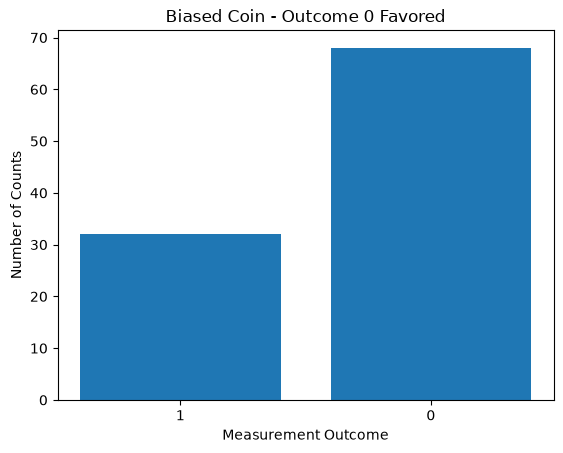

In [19]:

plt.bar(
    zero_counts.keys(),
    zero_counts.values()
)

plt.title("Biased Coin - Outcome 0 Favored")
plt.xlabel("Measurement Outcome")
plt.ylabel("Number of Counts")
plt.show()



## 4. Experiment 3 — Make Outcome 1 More Frequent

Now, we use the RY gate with an angle of 2π/3.

The predicted probabilities are:

P(0) = 25%

P(1) = 75%

Therefore, outcome 1 should occur more frequently than outcome 0.


In [20]:

one_circuit = QuantumCircuit(1, 1)

one_circuit.ry(2 * np.pi / 3, 0)
one_circuit.measure(0, 0)

print(one_circuit.draw())


     ┌──────────┐┌─┐
  q: ┤ Ry(2π/3) ├┤M├
     └──────────┘└╥┘
c: 1/═════════════╩═
                  0 


In [21]:

one_result = simulator.run(
    one_circuit, shots=100
).result()

one_counts = one_result.get_counts()

print("Outcome 1 is favored")
print("Predicted: 0 = 25%, 1 = 75%")
print("Actual counts:", one_counts)


Outcome 1 is favored
Predicted: 0 = 25%, 1 = 75%
Actual counts: {'1': 68, '0': 32}


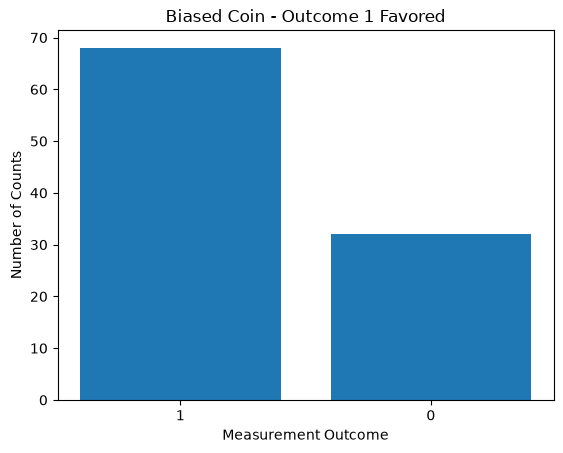

In [22]:

plt.bar(
    one_counts.keys(),
    one_counts.values()
)

plt.title("Biased Coin - Outcome 1 Favored")
plt.xlabel("Measurement Outcome")
plt.ylabel("Number of Counts")
plt.show()



## 5. Comparison of the Three Experiments

### Experiment 1: Fair Coin
The H gate ideally produces equal probabilities of 0 and 1.

### Experiment 2: Outcome 0 Favored
The RY(π/3) gate ideally produces 75% probability for 0 and 25% for 1.

### Experiment 3: Outcome 1 Favored
The RY(2π/3) gate ideally produces 25% probability for 0 and 75% for 1.

The measured counts may differ slightly because quantum measurement is probabilistic.


In [23]:

experiments = {
    "Fair Coin": fair_counts,
    "0 Favored": zero_counts,
    "1 Favored": one_counts
}

for name, counts in experiments.items():
    count_0 = counts.get("0", 0)
    count_1 = counts.get("1", 0)

    print(name)
    print("Count of 0:", count_0)
    print("Count of 1:", count_1)
    print("--------------------")


Fair Coin
Count of 0: 57
Count of 1: 43
--------------------
0 Favored
Count of 0: 68
Count of 1: 32
--------------------
1 Favored
Count of 0: 32
Count of 1: 68
--------------------



## 6. Conclusion

In this challenge, we created a single-qubit quantum circuit using Qiskit.

We used the H gate to create a fair quantum coin and the RY gate to create biased quantum coins.

By changing the rotation angle, we changed the probabilities of measuring 0 and 1. The histograms helped us compare the measurement results for 100 shots.

Thus, we successfully demonstrated how quantum gates can control the measurement probabilities of a qubit.



## 7. Challenge Question and Answer

**Question:** How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?

**Answer:** Quantum gates change the quantum state and the probability amplitudes of a qubit. The probability of each measurement outcome is the squared magnitude of its corresponding amplitude. The H gate ideally creates equal probabilities of 50% for 0 and 1. An RY gate with a suitable rotation angle can make one outcome more likely than the other. Therefore, changing the quantum gate or its rotation angle changes the measurement distribution.
